# Exercice 1 : le perceptron

## Porte AND

In [1]:
import numpy as np

X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y = np.array([0, 0, 0, 1])                  # AND ; pour NOR : np.array([1, 0, 0, 0])

np.random.seed(42)
w = np.random.randn(2)
b = np.random.randn()

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def predict(X, w, b):
    return sigmoid(X @ w + b)

def bce(y, p, eps=1e-12):                   # entropie croisée binaire
    return -np.mean(y * np.log(p + eps) + (1 - y) * np.log(1 - p + eps))

lr, epochs = 0.5, 2000
for i in range(epochs):
    p = predict(X, w, b)
    dz = p - y                              # gradient de l'entropie croisée
    w -= lr * (X.T @ dz) / len(X)
    b -= lr * dz.mean()
    if i % 200 == 0:
        print(f"Epoch {i}, Loss: {bce(y, p):.4f}")

print("Prédictions :", predict(X, w, b).round(3))

Epoch 0, Loss: 0.9452
Epoch 200, Loss: 0.1445
Epoch 400, Loss: 0.0819
Epoch 600, Loss: 0.0567
Epoch 800, Loss: 0.0431
Epoch 1000, Loss: 0.0347
Epoch 1200, Loss: 0.0290
Epoch 1400, Loss: 0.0249
Epoch 1600, Loss: 0.0218
Epoch 1800, Loss: 0.0194
Prédictions : [0.    0.02  0.02  0.972]


## Porte NOR

In [2]:
import numpy as np

X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y = np.array([1, 0, 0, 0])                 

np.random.seed(42)
w = np.random.randn(2)
b = np.random.randn()

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def predict(X, w, b):
    return sigmoid(X @ w + b)

def bce(y, p, eps=1e-12):                   # entropie croisée binaire
    return -np.mean(y * np.log(p + eps) + (1 - y) * np.log(1 - p + eps))

lr, epochs = 0.5, 2000
for i in range(epochs):
    p = predict(X, w, b)
    dz = p - y                              # gradient de l'entropie croisée
    w -= lr * (X.T @ dz) / len(X)
    b -= lr * dz.mean()
    if i % 200 == 0:
        print(f"Epoch {i}, Loss: {bce(y, p):.4f}")

print("Prédictions :", predict(X, w, b).round(3))

Epoch 0, Loss: 1.0348
Epoch 200, Loss: 0.0886
Epoch 400, Loss: 0.0467
Epoch 600, Loss: 0.0314
Epoch 800, Loss: 0.0235
Epoch 1000, Loss: 0.0188
Epoch 1200, Loss: 0.0156
Epoch 1400, Loss: 0.0133
Epoch 1600, Loss: 0.0116
Epoch 1800, Loss: 0.0103
Prédictions : [0.98  0.008 0.008 0.   ]


# Exercice 2 : Iris avec un MLP

In [3]:
%pip install numpy scikit-learn tensorflow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 8)                   │              40 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 3)                   │              27 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 67 (268.00 B)

 Trainable params: 67 (268.00 B)

 Non-trainable params: 0 (0.00 B)

Test Accuracy: 90.00%


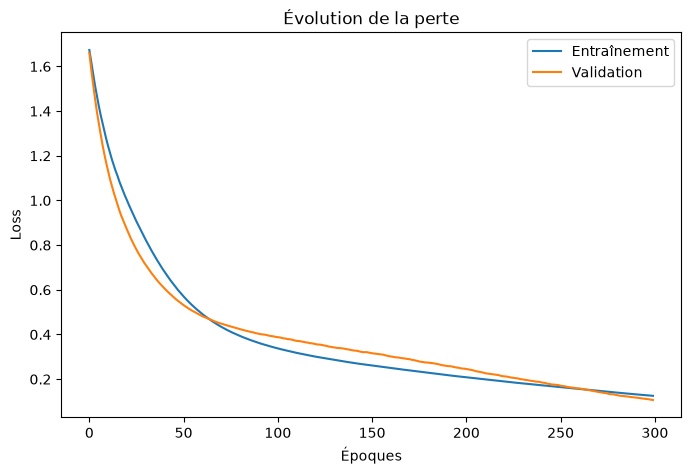

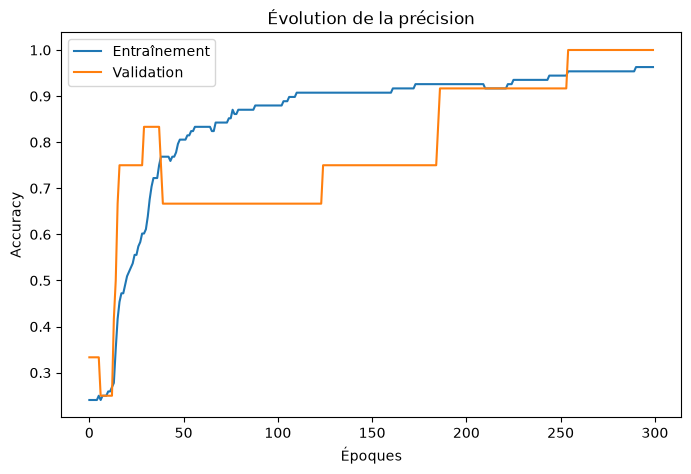

In [4]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import Dense
import matplotlib.pyplot as plt

X, y = load_iris(return_X_y=True)           # 4 features, classes 0, 1, 2

# 1. on sépare d'abord
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

# 2. on ajuste le scaler sur le train uniquement
scaler = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)

model = Sequential([
    Input(shape=(4,)),
    Dense(8, activation="relu"),
    Dense(3, activation="softmax"),
])
model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",   # y_train contient 0, 1, 2 (pas de one-hot)
              metrics=["accuracy"])
model.summary()

history = model.fit(X_train, y_train, epochs=300, batch_size=16,
                    validation_split=0.1, verbose=0)

loss, accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"Test Accuracy: {accuracy * 100:.2f}%")

# Graphique 1 : Loss
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Entraînement")
plt.plot(history.history["val_loss"], label="Validation")

plt.xlabel("Époques")
plt.ylabel("Loss")
plt.title("Évolution de la perte")
plt.legend()
plt.show()


# Graphique 2 : Accuracy
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Entraînement")
plt.plot(history.history["val_accuracy"], label="Validation")

plt.xlabel("Époques")
plt.ylabel("Accuracy")
plt.title("Évolution de la précision")
plt.legend()
plt.show()

In [5]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import Dense
from tensorflow.keras.callbacks import EarlyStopping

titanic = sns.load_dataset("titanic")
features = ["pclass", "sex", "age", "sibsp", "parch", "fare", "embarked"]
X, y = titanic[features], titanic["survived"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

# 1. valeurs manquantes : on utilise les statistiques du train
fill = {"age": X_train["age"].median(), "embarked": X_train["embarked"].mode()[0]}
X_train = X_train.fillna(fill)
X_test = X_test.fillna(fill)

# 2. variables catégorielles (mêmes colonnes pour train et test)
cat = ["sex", "embarked", "pclass"]
X_train = pd.get_dummies(X_train, columns=cat, drop_first=True)
X_test = pd.get_dummies(X_test, columns=cat, drop_first=True)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

# 3. normalisation des colonnes numériques (fit sur le train)
num = ["age", "fare"]
scaler = StandardScaler().fit(X_train[num])
X_train[num] = scaler.transform(X_train[num])
X_test[num] = scaler.transform(X_test[num])

# 4. conversion en tableaux numpy et vérification des dimensions
X_train = X_train.values.astype("float32")
X_test = X_test.values.astype("float32")
print("Shape X_train:", X_train.shape, "| Shape X_test:", X_test.shape)

model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(16, activation="relu"),
    Dense(1, activation="sigmoid"),
])
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

early = EarlyStopping(patience=10, restore_best_weights=True)
history = model.fit(X_train, y_train, epochs=100, batch_size=32,
                    validation_split=0.1, callbacks=[early], verbose=0)

pred = (model.predict(X_test) > 0.5).astype(int).ravel()
print(classification_report(y_test, pred))

Shape X_train: (712, 9) | Shape X_test: (179, 9)
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
              precision    recall  f1-score   support

           0       0.80      0.92      0.86       110
           1       0.83      0.64      0.72        69

    accuracy                           0.81       179
   macro avg       0.82      0.78      0.79       179
weighted avg       0.81      0.81      0.80       179



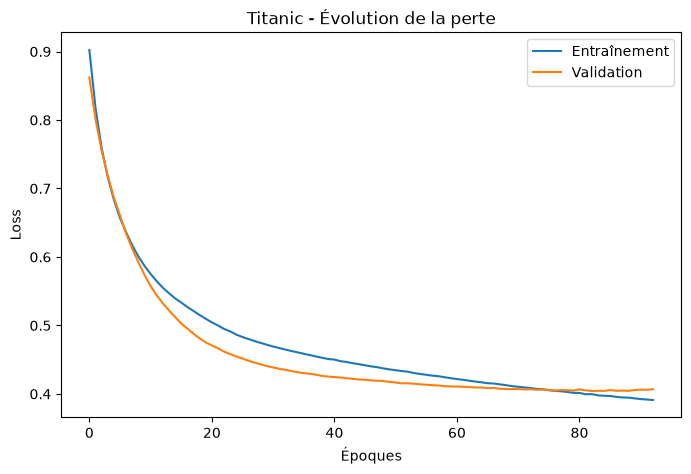

In [7]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Entraînement")
plt.plot(history.history["val_loss"], label="Validation")

plt.xlabel("Époques")
plt.ylabel("Loss")
plt.title("Titanic - Évolution de la perte")
plt.legend()
plt.show()

### 4 Neuronnes

In [8]:
model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(4, activation="relu"),
    Dense(1, activation="sigmoid"),
])
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

early = EarlyStopping(patience=10, restore_best_weights=True)
history = model.fit(X_train, y_train, epochs=100, batch_size=32,
                    validation_split=0.1, callbacks=[early], verbose=0)

pred = (model.predict(X_test) > 0.5).astype(int).ravel()
print(classification_report(y_test, pred))

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 
              precision    recall  f1-score   support

           0       0.81      0.87      0.84       110
           1       0.77      0.68      0.72        69

    accuracy                           0.80       179
   macro avg       0.79      0.78      0.78       179
weighted avg       0.80      0.80      0.80       179



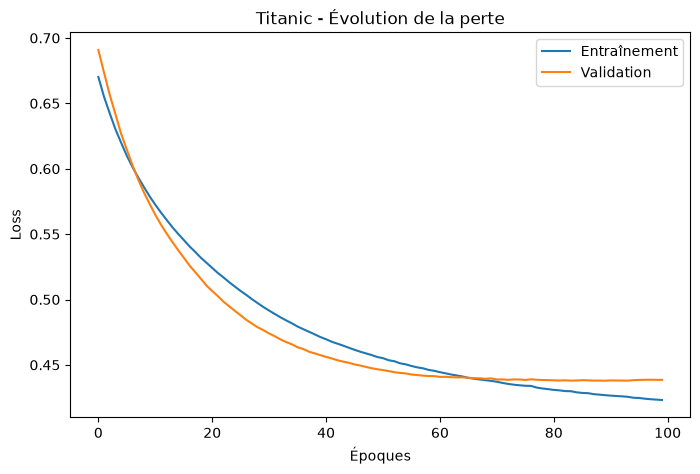

In [9]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Entraînement")
plt.plot(history.history["val_loss"], label="Validation")

plt.xlabel("Époques")
plt.ylabel("Loss")
plt.title("Titanic - Évolution de la perte")
plt.legend()
plt.show()

### 64 Neuronnes

In [10]:
model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(64, activation="relu"),
    Dense(1, activation="sigmoid"),
])
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

early = EarlyStopping(patience=10, restore_best_weights=True)
history = model.fit(X_train, y_train, epochs=100, batch_size=32,
                    validation_split=0.1, callbacks=[early], verbose=0)

pred = (model.predict(X_test) > 0.5).astype(int).ravel()
print(classification_report(y_test, pred))

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
              precision    recall  f1-score   support

           0       0.79      0.92      0.85       110
           1       0.82      0.61      0.70        69

    accuracy                           0.80       179
   macro avg       0.81      0.76      0.77       179
weighted avg       0.80      0.80      0.79       179



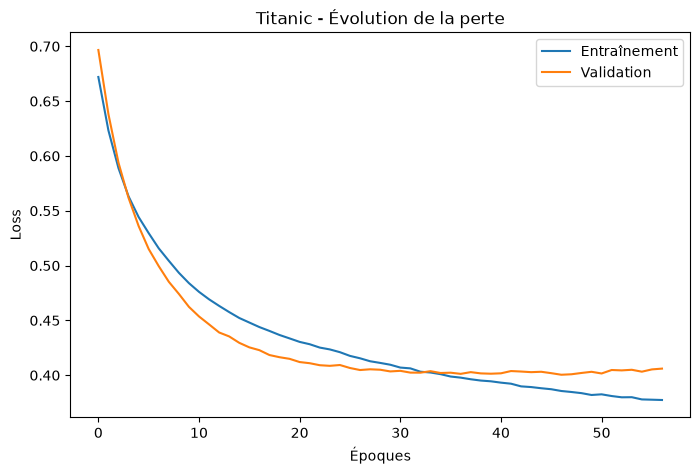

In [11]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Entraînement")
plt.plot(history.history["val_loss"], label="Validation")

plt.xlabel("Époques")
plt.ylabel("Loss")
plt.title("Titanic - Évolution de la perte")
plt.legend()
plt.show()

# Exercice 3 : un CNN sur MNIST

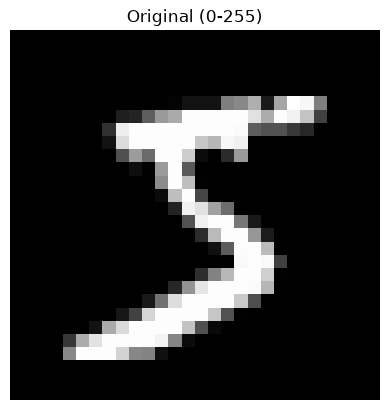

Formes finales : (60000, 28, 28, 1) (10000, 28, 28, 1)


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 3, 3, 64)            │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 576)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 128)                 │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_9 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 130,890 (511.29 KB)

 Trainable params: 130,890 (511.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 9s 9ms/step - accuracy: 0.9182 - loss: 0.2668 - val_accuracy: 0.9850 - val_loss: 0.0473
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.9781 - loss: 0.0740 - val_accuracy: 0.9875 - val_loss: 0.0447
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.9844 - loss: 0.0540 - val_accuracy: 0.9880 - val_loss: 0.0410
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.9864 - loss: 0.0445 - val_accuracy: 0.9905 - val_loss: 0.0326
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.9895 - loss: 0.0347 - val_accuracy: 0.9908 - val_loss: 0.0370
313/313 - 1s - 3ms/step - accuracy: 0.9906 - loss: 0.0316

Précision sur le test : 99.06%
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


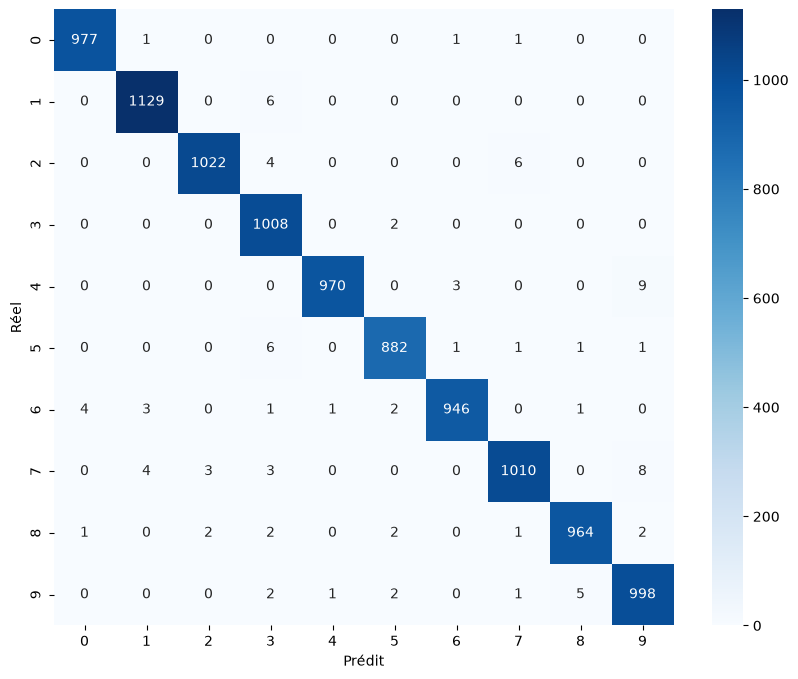

              precision    recall  f1-score   support

           0       0.99      1.00      1.00       980
           1       0.99      0.99      0.99      1135
           2       1.00      0.99      0.99      1032
           3       0.98      1.00      0.99      1010
           4       1.00      0.99      0.99       982
           5       0.99      0.99      0.99       892
           6       0.99      0.99      0.99       958
           7       0.99      0.98      0.99      1028
           8       0.99      0.99      0.99       974
           9       0.98      0.99      0.98      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



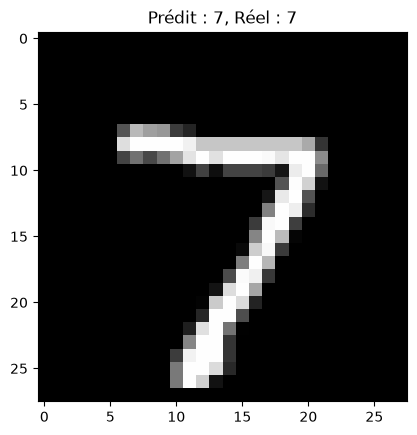

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras import datasets, layers, models, Input
from sklearn.metrics import confusion_matrix, classification_report

(X_train, y_train), (X_test, y_test) = datasets.mnist.load_data()

# une image brute (valeurs 0 à 255), avant toute transformation
img = X_train[y_train == 5][0]
plt.imshow(img, cmap="gray")
plt.title("Original (0-255)")
plt.axis("off")
plt.show()

# normalisation (0 à 1) puis ajout du canal : (N, 28, 28) -> (N, 28, 28, 1)
X_train = np.expand_dims(X_train.astype("float32") / 255.0, -1)
X_test = np.expand_dims(X_test.astype("float32") / 255.0, -1)
print("Formes finales :", X_train.shape, X_test.shape)

model = models.Sequential([
    Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(10, activation="softmax"),
])
model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
model.summary()

# la validation est prise dans le train : le test reste inconnu jusqu'à l'évaluation finale
history = model.fit(X_train, y_train, epochs=5, batch_size=64, validation_split=0.1)

loss, acc = model.evaluate(X_test, y_test, verbose=2)
print(f"\nPrécision sur le test : {acc * 100:.2f}%")

y_pred = np.argmax(model.predict(X_test), axis=1)

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Prédit")
plt.ylabel("Réel")
plt.show()

print(classification_report(y_test, y_pred))

plt.imshow(X_test[0].squeeze(), cmap="gray")
plt.title(f"Prédit : {y_pred[0]}, Réel : {y_test[0]}")
plt.show()

# **A FAIRE DIAPO**

# Exercice 4 : un CNN sur Fashion-MNIST

In [3]:
import tensorflow as tf

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()
print(x_train.shape, y_train.shape)        # (60000, 28, 28) (60000,)

classes = ["T-shirt/top", "Pantalon", "Pull", "Robe", "Manteau",
           "Sandale", "Chemise", "Sneaker", "Sac", "Bottine"]

(60000, 28, 28) (60000,)


In [4]:
X_train = x_train
X_test = x_test

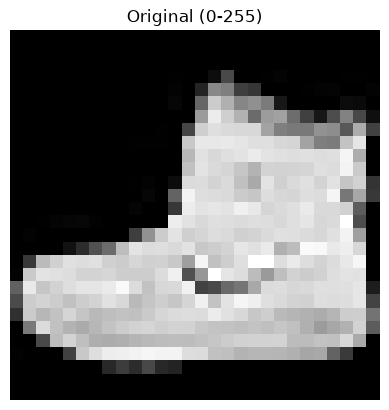

Formes finales : (60000, 28, 28, 1) (10000, 28, 28, 1)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 3, 3, 64)            │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 576)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 130,890 (511.29 KB)

 Trainable params: 130,890 (511.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 10s 10ms/step - accuracy: 0.7595 - loss: 0.6576 - val_accuracy: 0.8355 - val_loss: 0.4204
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.8541 - loss: 0.4080 - val_accuracy: 0.8762 - val_loss: 0.3285
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.8760 - loss: 0.3458 - val_accuracy: 0.8868 - val_loss: 0.3047
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.8884 - loss: 0.3136 - val_accuracy: 0.8915 - val_loss: 0.2932
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.8954 - loss: 0.2909 - val_accuracy: 0.9018 - val_loss: 0.2728
313/313 - 1s - 3ms/step - accuracy: 0.8993 - loss: 0.2796

Précision sur le test : 89.93%
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


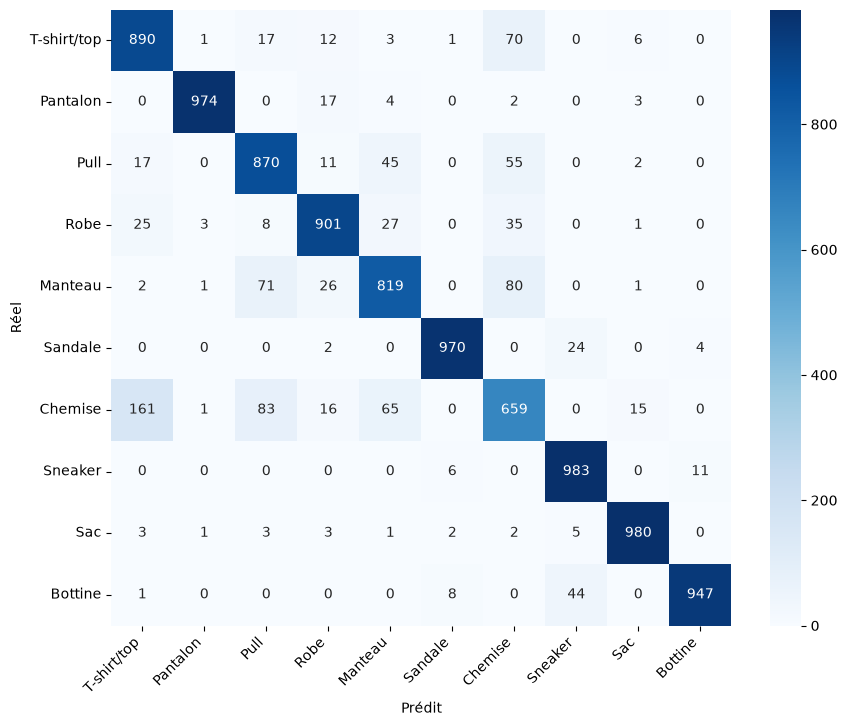

              precision    recall  f1-score   support

 T-shirt/top       0.81      0.89      0.85      1000
    Pantalon       0.99      0.97      0.98      1000
        Pull       0.83      0.87      0.85      1000
        Robe       0.91      0.90      0.91      1000
     Manteau       0.85      0.82      0.83      1000
     Sandale       0.98      0.97      0.98      1000
     Chemise       0.73      0.66      0.69      1000
     Sneaker       0.93      0.98      0.96      1000
         Sac       0.97      0.98      0.98      1000
     Bottine       0.98      0.95      0.97      1000

    accuracy                           0.90     10000
   macro avg       0.90      0.90      0.90     10000
weighted avg       0.90      0.90      0.90     10000



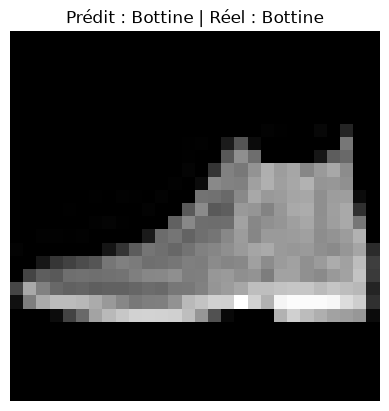

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow.keras import datasets, layers, models, Input
from sklearn.metrics import confusion_matrix, classification_report

img = X_train[0]

plt.imshow(img, cmap="gray")
plt.title("Original (0-255)")
plt.axis("off")
plt.show()

X_train = np.expand_dims(X_train.astype("float32") / 255.0, -1)
X_test = np.expand_dims(X_test.astype("float32") / 255.0, -1)

print("Formes finales :", X_train.shape, X_test.shape)

model = models.Sequential([
    Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(10, activation="softmax"),
])

model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

model.summary()

history = model.fit(
    X_train, y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1
)

loss, acc = model.evaluate(X_test, y_test, verbose=2)

print(f"\nPrécision sur le test : {acc * 100:.2f}%")

y_pred = np.argmax(model.predict(X_test), axis=1)

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=classes, yticklabels=classes)

plt.xlabel("Prédit")
plt.ylabel("Réel")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.show()

print(classification_report(y_test, y_pred, target_names=classes))

plt.imshow(X_test[0].squeeze(), cmap="gray")
plt.title(f"Prédit : {classes[y_pred[0]]} | Réel : {classes[y_test[0]]}")
plt.axis("off")
plt.show()

# Exercice 5 :  Un RNN qui génère du texte 